# 03 - Visualización y Catálogo de Gráficos del Proyecto

Este notebook orquesta, interpreta y exporta el conjunto integral de figuras visuales utilizadas en el **Informe Técnico** y la **Defensa Oral** del proyecto.
Las figuras resultantes se persisten automáticamente en el directorio `reports/figures/` en formato PNG con resolución de 150 DPI para su inserción directa en el reporte final.

---

### Arquitectura de Persistencia Políglota y Orquestación:
- **Lectura Relacional (SQLite):** Consume la tabla inmutable `datos_limpios` desde `data/processed/deptos.db` mediante `src.db_sql.load_clean_data()`.
- **Lectura Documental (MongoDB Atlas):** Consume métricas consolidadas (`metricas`), inferencias out-of-time (`predicciones`) y experimentos de integridad (`leakage`) mediante `src.db_mongo.load_run()`.
- **Modelos Serializados:** Carga el estimador ensamble optimizado desde `models/results.joblib` para análisis de importancia por permutación.
- **Desacople Arquitectónico:** El notebook cumple un rol exclusivamente analítico y de orquestación; la lógica gráfica especializada (estilos seaborn, configuraciones de ejes, paletas y exportación a disco) reside de forma modular en `src/visualization.py`.

### Catálogo de Figuras del Informe:
1. `precio_m2_por_anio.png`: Evolución anual de precios por m² y cortes empíricos de terciles condicionales.
2. `comparacion_modelos.png`: Desempeño multimodelo facetado por escenario de evaluación (Aleatorio vs Temporal).
3. `matrices_confusion_aleatorio.png` y `matrices_confusion_temporal.png`: Patrones de acierto diagonal y confusión entre clases contiguas.
4. `accuracy_por_anio_temporal.png`: Diagnóstico de estabilidad out-of-time y envejecimiento predictivo (2014-2016).
5. `importancia_variables.png`: Ranking de predictoras del Random Forest mediante caída empírica de exactitud por permutación.
6. `leakage.png`: Evidencia empírica de la distorsión introducida por variables contaminantes prohibidas.

> **Precondiciones de Ejecución:**
> Requiere haber ejecutado previamente `01_eda.ipynb` (genera SQLite) y `02_modelado.ipynb` (persiste en MongoDB y exporta `models/results.joblib`), o bien haber ejecutado el pipeline integral mediante `python main.py`.
> Puede ejecutarse celda a celda de forma interactiva o automatizado mediante `python main.py` con inyección de parámetros vía **Papermill**.

In [1]:
# =============================================================================
# PARÁMETROS INYECTABLES VÍA PAPERMILL (main.py)
# =============================================================================
# Si el notebook se ejecuta interactivamente, se adoptan los valores por defecto.
# Al invocarse desde main.py con flags CLI, Papermill inyecta celdas dinámicas.

# Flag global para habilitar/deshabilitar la exportación de figuras en reports/figures/
save_figures = True

# Tamaño de la submuestra para el cómputo de importancia por permutación.
# Justificación metodológica: n=8_000 ofrece convergencia estadística robusta
# reduciendo el tiempo de CPU en ~75% respecto al dataset completo de test.
sample_perm = 8_000

## 1. Configuración del entorno y carga de datos limpios

Se establece la raíz del proyecto en el path de Python, se inicializa el mecanismo de recarga dinámica de módulos (`autoreload`) para reflejar modificaciones en `src/` sin reiniciar el kernel, y se recupera la **Tabla 1** desde la base relacional SQLite (`data/processed/deptos.db`).

La función `load_clean_data()` garantiza la integridad física de los tipos de datos y la inmutabilidad del dataset maestro procesado.

In [2]:
import sys; sys.path.append("..")

# Recarga automática de cambios en librerías del proyecto (src/)
%load_ext autoreload
%autoreload 2

import joblib
import pandas as pd
import config
from src.db_sql import load_clean_data
from src.features import get_xy, split_data
from src.db_mongo import load_run
from src import visualization as viz
from src.logger_setup import flush_mongo_logs

# Recuperación del dataset maestro limpio desde la base relacional local (SQLite)
df = load_clean_data()
print(f"Dataset maestro cargado exitosamente desde SQLite: {df.shape[0]:,} observaciones, {df.shape[1]} columnas.")

2026-11-15 20:11:06,927 | INFO     | src.db_sql | Tabla 'datos_limpios' leída: 174116 filas, 20 columnas


Dataset maestro cargado exitosamente desde SQLite: 174,116 observaciones, 20 columnas.


## 2. Evolución temporal de PRECIO_M2 y justificación de los cortes por año

### Marco Teórico y Justificación de Negocio Inmobiliario:
En economías caracterizadas por inflación monetaria persistente y apreciación diferencial en dólares del metro cuadrado, el nivel nominal de precios experimenta un incremento sistemático a lo largo del tiempo (2001-2016).

Si se aplicaran **umbrales fijos globales** para categorizar los segmentos inmobiliarios:
$$\text{Segmento} = f(\text{PRECIO\_M2})$$
los avisos de los primeros períodos históricos quedarían asignados casi en su totalidad al segmento `bajo`, mientras que los avisos contemporáneos se concentrarían en `alto`. Bajo ese esquema defectuoso, un clasificador aprendería a predecir la **antigüedad o época del aviso publicitario** en lugar de capturar la **calidad intrínseca, categoría constructiva y ubicación relativa** del departamento.

### Solución Metodológica:
Se computan los terciles (percentiles 33.3% y 66.6%) **condicionados a cada año de publicación**:
$$P(\text{PRECIO\_M2} \le q_{33} \mid \text{AÑO} = t) = \frac{1}{3}, \quad P(\text{PRECIO\_M2} \le q_{66} \mid \text{AÑO} = t) = \frac{2}{3}$$
Esto garantiza clases balanceadas de forma uniforme ($33.3\%$ para `bajo`, `medio` y `alto` por cada año), desacoplando la variación macroeconómica temporal de la tarea de clasificación supervisada.

2026-11-15 20:11:12,702 | INFO     | src.visualization | Figura guardada: precio_m2_por_anio.png


Matriz de umbrales anuales (USD/m²) calculados por terciles condicionales:


,tercil 1/3,mediana,tercil 2/3
AÑO,,,
2001,800.0,871.8,950.0
2002,398.8,471.4,553.6
2003,497.6,571.4,666.7
2004,668.8,773.3,887.0
2005,760.0,866.7,983.3
2006,956.5,1052.6,1171.7
2007,1065.8,1206.1,1387.1
2008,1339.3,1533.3,1721.3
2009,1427.3,1608.3,1808.1


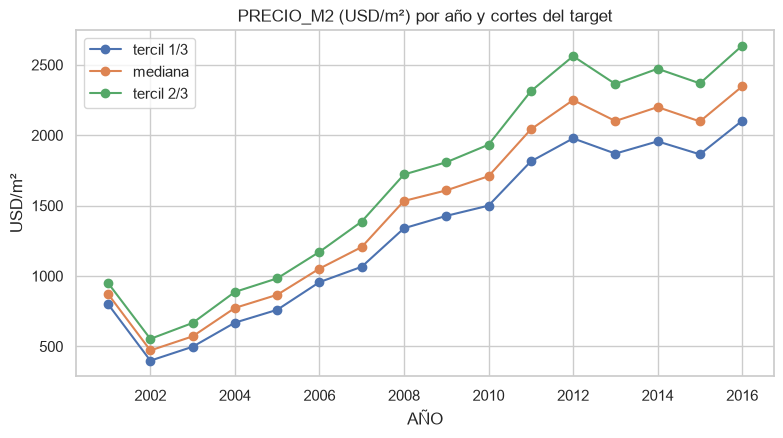

In [3]:
# Generación y persistencia de la figura 'precio_m2_por_anio.png'
# Muestra la mediana histórica y el ensanchamiento progresivo de las bandas de terciles.
q_cortes = viz.plot_price_by_year(df)

# Visualización tabular de la matriz de cortes anuales para referencia analítica
print("Matriz de umbrales anuales (USD/m²) calculados por terciles condicionales:")
display(q_cortes.round(1))

## 3. Comparación global de modelos entre escenarios (Aleatorio vs Temporal)

### Marco Teórico y Rigor Metodológico:
Para evaluar de manera exhaustiva los algoritmos de clasificación, se comparan sus métricas bajo dos regímenes de partición con propósitos complementarios:
1. **Escenario Aleatorio (Split 80/20 Estratificado):**
   - Evalúa la capacidad de **interpolación contemporánea**: el conjunto de entrenamiento y el de prueba comparten la misma ventana temporal de distribución de avisos.
2. **Escenario Temporal (Split Out-of-Time):**
   - Evalúa la capacidad de **extrapolación prospectiva**: se entrena con avisos de 2001 a 2013 y se evalúa sobre los años 2014, 2015 y 2016 (datos no observados en el tiempo).
   - Simula las condiciones operativas de un sistema de valuación inmobiliaria puesto en producción.

### Justificación de Métricas Macro-Promediadas:
Se priorizan `f1_macro` y `recall_macro` por sobre la exactitud simple (`accuracy`), ya que calculan la media no ponderada de las tres clases, garantizando que un clasificador con deficiencias en alguna clase específica sea penalizado de forma rigurosa.

2026-11-15 20:11:17,804 | INFO     | src.db_mongo | Mongo 'metricas' [aleatorio]: 4 documentos leídos (run_id=20261115_191716)
2026-11-15 20:11:17,811 | INFO     | src.db_mongo | Mongo 'metricas' [temporal]: 4 documentos leídos (run_id=20261115_191716)


Tabla comparativa de métricas consolidadas (MongoDB Atlas):


,escenario,model,accuracy,precision_macro,recall_macro,f1_macro
0,aleatorio,logreg,0.6191,0.6132,0.6191,0.6153
1,aleatorio,random_forest,0.6783,0.6774,0.6783,0.6778
2,aleatorio,xgboost,0.6693,0.6670,0.6693,0.6680
3,aleatorio,dummy,0.3325,0.3325,0.3325,0.3325
4,temporal,logreg,0.6078,0.6016,0.6078,0.6037
5,temporal,random_forest,0.6403,0.6407,0.6403,0.6405
6,temporal,xgboost,0.6368,0.6342,0.6368,0.6353
7,temporal,dummy,0.3334,0.3334,0.3334,0.3334


2026-11-15 20:11:18,207 | INFO     | src.visualization | Figura guardada: comparacion_modelos.png


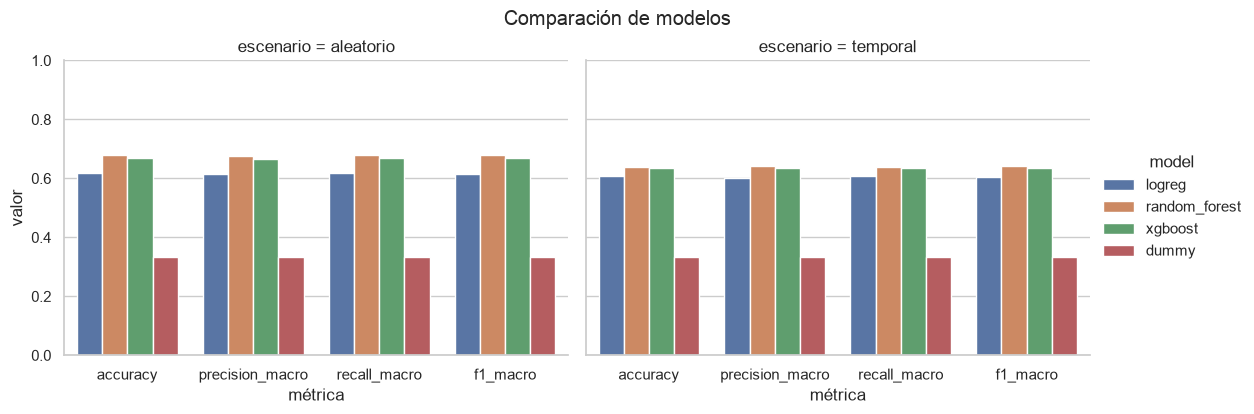

In [4]:
# Consulta a MongoDB Atlas: recuperación de documentos de métricas en ambos escenarios
met = pd.concat([load_run("metricas", e) for e in ("aleatorio", "temporal")], ignore_index=True)

# Selección de atributos clave para auditoría tabular
cols_resumen = ["escenario", "model", "accuracy", "precision_macro", "recall_macro", "f1_macro"]

print("Tabla comparativa de métricas consolidadas (MongoDB Atlas):")
display(met[cols_resumen].round(4))

# Generación y exportación de 'comparacion_modelos.png' (facetado por escenario)
viz.plot_model_comparison(met)

## 4. Matrices de confusión normalizadas por fila

### Marco Teórico e Interpretación de la Tasa de Acierto:
La normalización por fila representa formalmente la probabilidad condicional empírica de clasificar en $\hat{Y} = j$ dado que la clase real es $Y = i$:
$$M_{i, j} = P(\hat{Y} = j \mid Y = i) = \frac{\text{Conteo}(Y = i, \hat{Y} = j)}{\sum_{k} \text{Conteo}(Y = i, \hat{Y} = k)}$$
La diagonal principal expresa el **Recall de cada clase**.

### Matriz de Costos y Penalización de Errores:
En un problema con ordenamiento implícito (`bajo` $<$ `medio` $<$ `alto`):
- **Errores contiguos (`bajo` $\leftrightarrow$ `medio`, `medio` $\leftrightarrow$ `alto`):** Son tolerables y comprensibles, ya que ocurren en zonas de frontera donde las características del departamento rozan los límites de los percentiles.
- **Errores extremos (`bajo` $\leftrightarrow$ `alto`):** Constituyen fallas críticas del sistema predictivo. Un clasificador confiable debe mantener las celdas de las esquinas opuestas cercanas a $0\%$.


[Visualización] Procesando matrices de confusión para escenario: ALEATORIO


2026-11-15 20:11:21,483 | INFO     | src.visualization | Figura guardada: matrices_confusion_aleatorio.png



[Visualización] Procesando matrices de confusión para escenario: TEMPORAL


2026-11-15 20:11:22,054 | INFO     | src.visualization | Figura guardada: matrices_confusion_temporal.png


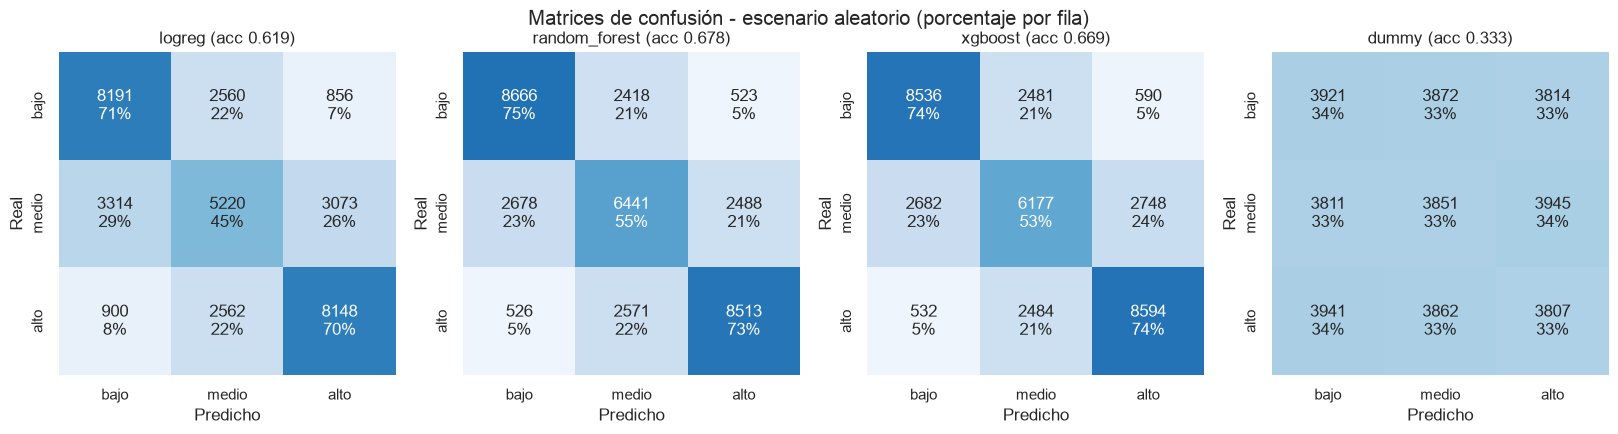

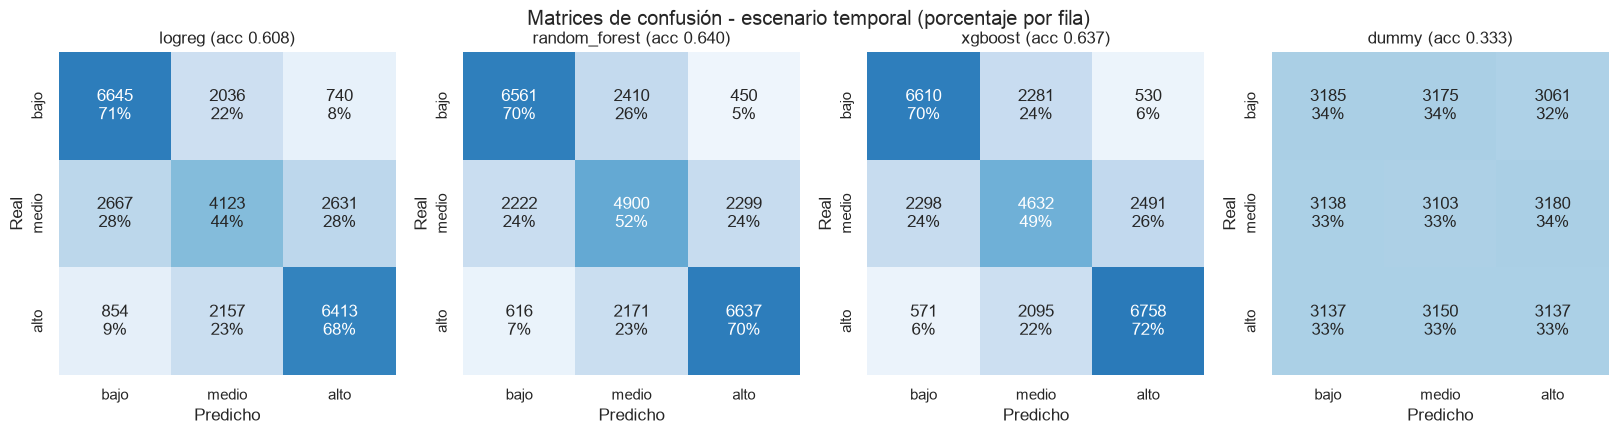

In [5]:
# Generación y exportación secuencial de matrices de confusión por escenario:
# 'matrices_confusion_aleatorio.png' y 'matrices_confusion_temporal.png'
for e in ("aleatorio", "temporal"):
    df_escenario = met[met["escenario"] == e]
    print(f"\n[Visualización] Procesando matrices de confusión para escenario: {e.upper()}")
    # La función interna normaliza los conteos absolutos por fila a proporciones (0.0 a 1.0)
    viz.plot_confusion_matrices(df_escenario, e)

## 5. Precisión temporal año a año (Escenario Out-of-Time)

### Marco Teórico y Diagnóstico de Concept Drift:
El rendimiento out-of-time global puede enmascarar dinámicas de degradación temporal. Esta sección evalúa el comportamiento del modelo en cada año del conjunto de prueba (2014, 2015, 2016) tras haber sido entrenado hasta 2013:
- Si la exactitud se mantiene estable en el trienio, el modelo demuestra **robustez frente a cambios estructurales** del mercado inmobiliario.
- Si la exactitud cae monótonamente conforme nos alejamos de 2013, evidencia **desfase de distribución (*concept drift*)**, sugiriendo la necesidad de reentrenamientos periódicos programados.

2026-11-15 20:11:25,604 | INFO     | src.db_mongo | Mongo 'predicciones' [temporal]: 113064 documentos leídos (run_id=20261115_191716)
2026-11-15 20:11:25,682 | INFO     | src.visualization | Figura guardada: accuracy_por_anio_temporal.png


Exactitud temporal (Accuracy) desagregada por año y algoritmo predictivo:


modelo,logreg,random_forest,xgboost
AÑO,,,
2014,0.616,0.657,0.650
2015,0.615,0.646,0.643
2016,0.563,0.573,0.579


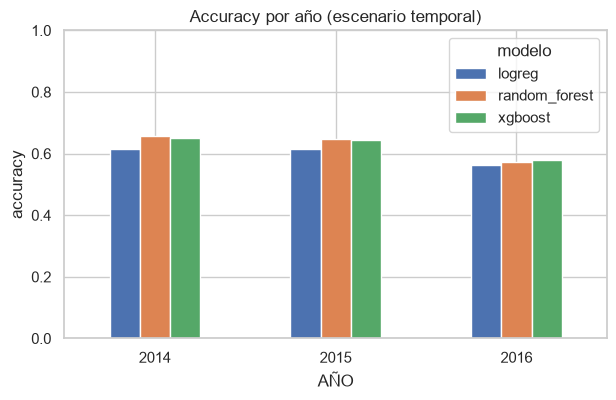

In [6]:
# Carga de inferencias individuales (predicciones) desde MongoDB Atlas
pred_t = load_run("predicciones", "temporal")

# Se descarta deliberadamente la línea base dummy (accuracy constante ~0.33)
# para evitar que comprima la escala vertical del gráfico, permitiendo distinguir
# con nitidez la separación de desempeño entre Random Forest, XGBoost y Logística.
pred_modelos = pred_t[pred_t["modelo"] != "dummy"]

# Generación y exportación de 'accuracy_por_anio_temporal.png'
tasa_anual = viz.plot_accuracy_by_year(pred_modelos, df)

print("Exactitud temporal (Accuracy) desagregada por año y algoritmo predictivo:")
display(tasa_anual.round(4))

## 6. Importancia de características por permutación (Random Forest)

### Fundamentación Metodológica y KaTeX:
A diferencia de la métrica por impureza intrínseca (MDI / Mean Decrease in Impurity basada en Gini), que favorece espuriamente variables continuas ruidosas o de alta cardinalidad, la **importancia por permutación** evalúa el impacto sobre el conjunto de prueba independiente ($X_{\text{test}}, y_{\text{test}}$):

$$\Delta \text{Exactitud}_j = \text{Exactitud}(M, X_{\text{test}}, y_{\text{test}}) - \text{Exactitud}(M, X_{\text{test}}^{\pi(j)}, y_{\text{test}})$$

donde $X_{\text{test}}^{\pi(j)}$ representa el conjunto de prueba donde los valores de la variable $j$ han sido permutados aleatoriamente, destruyendo su relación predictiva con el target:
- Una caída acusada ($\Delta \text{Exactitud} > 0.05$) indica una variable crítica cuya ausencia desestabiliza las decisiones del clasificador.
- Valores cercanos a cero denotan variables accesorias o cuya información está redundada por otros atributos.

2026-11-15 20:11:33,890 | INFO     | src.features | X: (174116, 12) | y: (174116,) | predictoras: ['M2', 'AMBIENTES', 'ANTIGUEDAD', 'BAÑOS', 'BAULERA', 'COCHERA', 'LAVADERO', 'TERRAZA', 'LAT', 'LON', 'BARRIO', 'ORIENT']
2026-11-15 20:11:34,036 | INFO     | src.features | Train: 139292 filas | Test: 34824 filas
2026-11-15 20:11:34,039 | INFO     | src.features | Target en train:
SEGMENTO
alto     0.333
medio    0.333
bajo     0.333
2026-11-15 20:11:34,040 | INFO     | src.features | Target en test:
SEGMENTO
alto     0.333
medio    0.333
bajo     0.333


Calculando importancia de variables por permutación (muestra: 8,000 registros)...


2026-11-15 20:11:37,855 | INFO     | src.visualization | Figura guardada: importancia_variables.png



Ranking de predictoras ordenado por caída de Exactitud (Permutation Importance):


,variable,caida_accuracy,desvio
0,LAT,2.308333e-01,0.004529
1,LON,1.004167e-01,0.002758
2,M2,9.620833e-02,0.003011
3,ANTIGUEDAD,5.358333e-02,0.004053
4,BARRIO,4.212500e-02,0.002298
5,COCHERA,1.995833e-02,0.000850
6,AMBIENTES,1.379167e-02,0.000825
7,BAÑOS,5.000000e-03,0.000530
8,ORIENT,4.291667e-03,0.000312
9,LAVADERO,1.875000e-03,0.001075


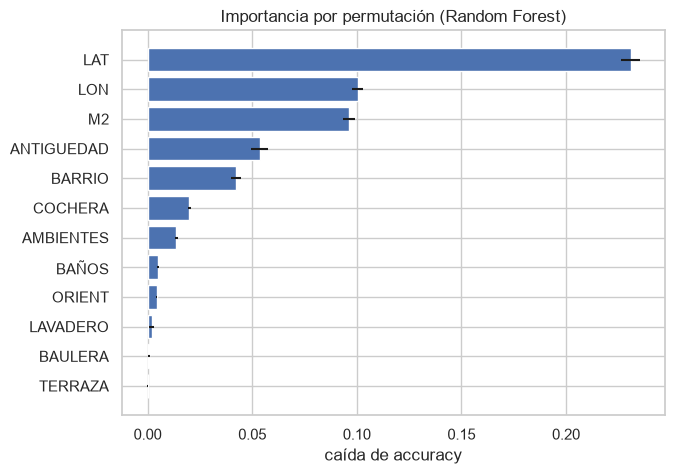

In [7]:
# Carga del artefacto binario entrenado (Random Forest optimizado con mejores hiperparámetros)
results = joblib.load(config.MODELS_DIR / "results.joblib")
rf_model = results["random_forest"]["model"]

# Reconstrucción de la partición de prueba estandarizada con semilla determinista
X, y = get_xy(df)
_, X_test, _, y_test = split_data(X, y)

# Computa la importancia por permutación sobre la submuestra configurada
print(f"Calculando importancia de variables por permutación (muestra: {sample_perm:,} registros)...")
imp = viz.plot_permutation_importance(rf_model, X_test, y_test, n=sample_perm)

print("\nRanking de predictoras ordenado por caída de Exactitud (Permutation Importance):")
display(imp)

## 7. Demostración visual de Fuga de Información (Data Leakage)

### Marco Teórico y Valor Pedagógico:
Un componente central del trabajo práctico y de la evaluación técnica consiste en la detección de variables contaminantes (*data leakage*):
- **Modelo Genuino:** Entrenado exclusivamente con variables predictoras legítimas observables ex-ante (`M2`, `BAÑOS`, `BARRIO`, `LAT`, `LON`, `COCHERAS`, `COMUNA`, etc.).
- **Variantes Contaminadas:**
  - Inclusión de `PRECIO_M2`: Variable a partir de la cual se construyó el target (fuga matemática directa, exactitud $\approx 100\%$).
  - Inclusión de `DOLARES`: Introduce colinealidad espuria con el nivel de precios.
  - Inclusión de `AÑO`: Permite memorizar el nivel promedio anual de la inflación.

El gráfico exportado ilustra el impacto de estas anomalías en la métrica final, fundamentando las decisiones de exclusión en la etapa de ingeniería de características.

2026-11-15 20:11:46,521 | INFO     | src.db_mongo | Mongo 'leakage' [leakage]: 5 documentos leídos (run_id=20261115_191716)
2026-11-15 20:11:46,613 | INFO     | src.visualization | Figura guardada: leakage.png


Resultados de la auditoría de Data Leakage (comparativa contra modelo legítimo):


,variante,accuracy,f1_macro,delta_vs_modelo_real
0,sin DOLARES (modelo real),0.6478,0.6438,0.0000
1,"sin DOLARES, con AÑO",0.6508,0.6468,0.0030
2,con DOLARES,0.6906,0.6867,0.0429
3,con DOLARES + AÑO,0.7088,0.7053,0.0610
4,con PRECIO_M2 + AÑO,0.8544,0.8542,0.2066



[OK] Catálogo visual del informe generado y exportado exitosamente en reports/figures/


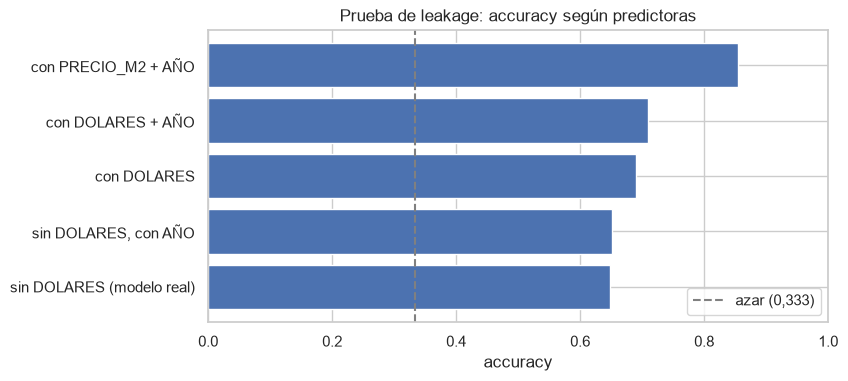

In [8]:
# Carga de la colección 'leakage' persistida en MongoDB Atlas
leak_df = load_run("leakage", "leakage")

# Generación y exportación de 'leakage.png' (gráfico de barras comparativo)
viz.plot_leakage(leak_df)

print("Resultados de la auditoría de Data Leakage (comparativa contra modelo legítimo):")
display(leak_df[["variante", "accuracy", "f1_macro", "delta_vs_modelo_real"]].round(4))

# Vaciado síncrono del buffer de logging hacia MongoDB Atlas antes de culminar
flush_mongo_logs()
print("\n[OK] Catálogo visual del informe generado y exportado exitosamente en reports/figures/")